Минимальная дата: 2006-12-16 17:24:00
Максимальная дата: 2010-11-26 21:02:00
Количество строк: 2075259
NaN в DateTime: 0

Количество строк с дублирующимися DateTime: 0
Количество уникальных временных меток, имеющих дубли: 0

Распределение интервалов между соседними timestamp:


0 days 00:01:00    2075258
Name: count, dtype: int64


Количество интервалов ровно 1 минута: 2075258
Количество интервалов больше 1 минуты: 0

Ожидаемое число минут: 2075259
Фактическое число уникальных timestamp: 2075259
Отсутствующих минут: 0

Строк с хотя бы одним NaN в измерениях: 25979
Доля таких строк: 1.252%
Строк, где отсутствуют сразу все 7 измерений: 25979
Строк, где отсутствует только часть измерений: 0

Пропуски измерений по месяцам:


,sum,count,missing_%
month,,,
2006-12,4,21996,0.018185
2007-01,2,44640,0.004480
2007-02,2,40320,0.004960
2007-03,1,44640,0.002240
2007-04,3723,43200,8.618056
2007-05,0,44640,0.000000
2007-06,43,43200,0.099537
2007-07,131,44640,0.293459
2007-08,22,44640,0.049283



Пропуски измерений по часам суток:


,sum,count,missing_%
hour,,,
0,969,86460,1.120749
1,1020,86460,1.179736
2,1021,86460,1.180893
3,1032,86460,1.193616
4,1143,86460,1.321999
5,1200,86460,1.387925
6,1201,86460,1.389082
7,1176,86460,1.360167
8,1165,86460,1.347444


Аудит месяцев:


,rows,unique_timestamps,rows_with_nan,first_timestamp,last_timestamp,expected_minutes,all_minutes_present,no_duplicates,no_measurement_nan,full_calendar_boundaries,complete_month
month,,,,,,,,,,,
2006-12,21996,21996,4,2006-12-16 17:24:00,2006-12-31 23:59:00,44640,False,True,False,False,False
2007-01,44640,44640,2,2007-01-01 00:00:00,2007-01-31 23:59:00,44640,True,True,False,True,False
2007-02,40320,40320,2,2007-02-01 00:00:00,2007-02-28 23:59:00,40320,True,True,False,True,False
2007-03,44640,44640,1,2007-03-01 00:00:00,2007-03-31 23:59:00,44640,True,True,False,True,False
2007-04,43200,43200,3723,2007-04-01 00:00:00,2007-04-30 23:59:00,43200,True,True,False,True,False
2007-05,44640,44640,0,2007-05-01 00:00:00,2007-05-31 23:59:00,44640,True,True,True,True,True
2007-06,43200,43200,43,2007-06-01 00:00:00,2007-06-30 23:59:00,43200,True,True,False,True,False
2007-07,44640,44640,131,2007-07-01 00:00:00,2007-07-31 23:59:00,44640,True,True,False,True,False
2007-08,44640,44640,22,2007-08-01 00:00:00,2007-08-31 23:59:00,44640,True,True,False,True,False



Полностью заполненные календарные месяцы:
['2007-05', '2008-04', '2008-09']

Количество полных месяцев: 3


month,2007-05,2008-04,2008-09
hour,,,
0,0.529941,0.797469,0.462752
1,0.388802,0.624651,0.404659
2,0.343177,0.492433,0.366183
3,0.325015,0.460032,0.370969
4,0.320585,0.428302,0.355149
5,0.321343,0.415472,0.385362
6,0.714482,0.690743,0.804497
7,1.160796,1.452736,1.837257
8,1.381011,1.385911,1.460422


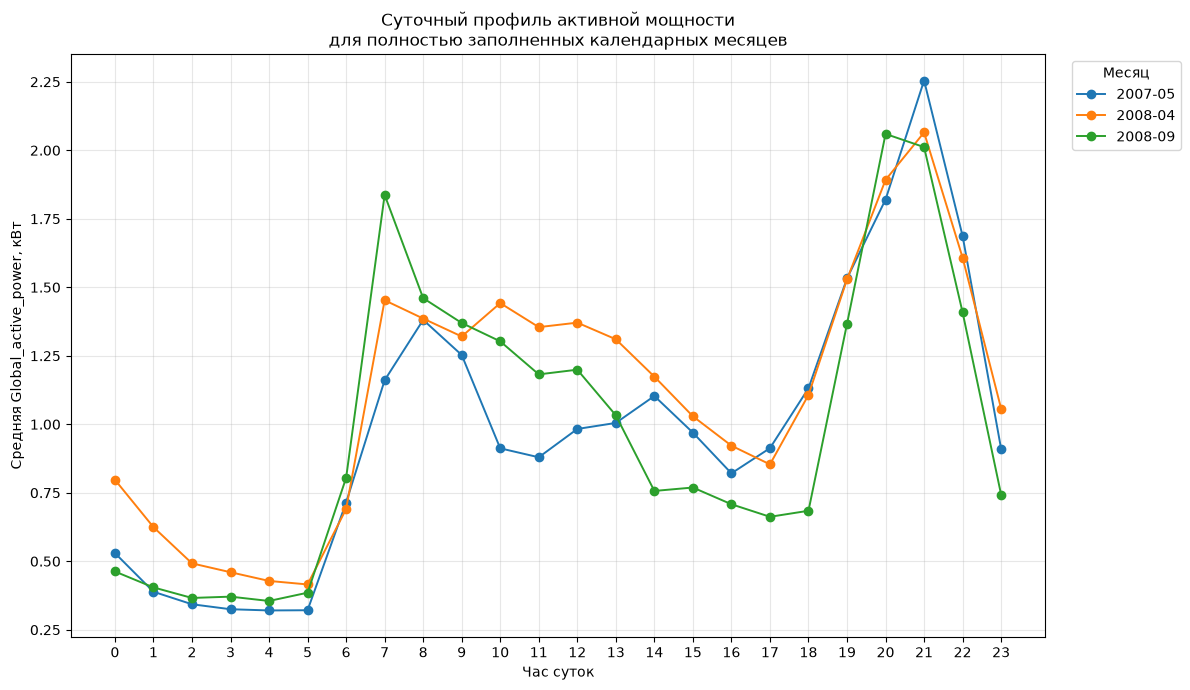

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Названия измерительных признаков
measure_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
]

path = Path("/Users/danklo/Downloads/household_power_consumption.txt")

na_values = ["?", "NA", ""]

df = pd.read_csv(
    path,
    sep=";",
    header=0,
    na_values=na_values,
    keep_default_na=True,
    dtype={"Date": "string", "Time": "string"},
    low_memory=False,
    encoding="latin1",
    decimal="."
)

df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)


# Работаем с временными метками отдельно, не изменяя df
ts = df["DateTime"]

# --------------------------------------------------
# 1. Базовая проверка DateTime
# --------------------------------------------------

print("Минимальная дата:", ts.min())
print("Максимальная дата:", ts.max())
print("Количество строк:", len(df))
print("NaN в DateTime:", ts.isna().sum())

# --------------------------------------------------
# 2. Дубли временных меток
# --------------------------------------------------

duplicate_mask = ts.duplicated(keep=False)

print("\nКоличество строк с дублирующимися DateTime:",
      duplicate_mask.sum())

print("Количество уникальных временных меток, имеющих дубли:",
      ts[duplicate_mask].nunique())

if duplicate_mask.any():
    print("\nПримеры дублей:")
    display(
        df.loc[duplicate_mask, ["DateTime"] + measure_cols]
          .sort_values("DateTime")
          .head(20)
    )

# --------------------------------------------------
# 3. Проверка шага между соседними timestamp
# --------------------------------------------------

# Уникальные временные метки в хронологическом порядке
unique_ts = pd.DatetimeIndex(ts.dropna().unique()).sort_values()

time_diff = unique_ts.to_series().diff()

print("\nРаспределение интервалов между соседними timestamp:")
display(time_diff.value_counts().sort_index().head(20))

print("\nКоличество интервалов ровно 1 минута:",
      (time_diff == pd.Timedelta(minutes=1)).sum())

print("Количество интервалов больше 1 минуты:",
      (time_diff > pd.Timedelta(minutes=1)).sum())

# --------------------------------------------------
# 4. Явно ищем отсутствующие минуты
# --------------------------------------------------

# date_range создаёт ожидаемую минутную сетку между min и max
expected_ts = pd.date_range(
    start=unique_ts.min(),
    end=unique_ts.max(),
    freq="min"
)

missing_ts = expected_ts.difference(unique_ts)

print("\nОжидаемое число минут:", len(expected_ts))
print("Фактическое число уникальных timestamp:", len(unique_ts))
print("Отсутствующих минут:", len(missing_ts))

if len(missing_ts) > 0:
    print("\nПервые отсутствующие timestamp:")
    display(pd.Series(missing_ts[:20], name="missing_timestamp"))

# --------------------------------------------------
# 5. Пропуски измерений по строкам
# --------------------------------------------------

# Есть ли хотя бы один NaN среди измерений в строке
row_has_nan = df[measure_cols].isna().any(axis=1)

print("\nСтрок с хотя бы одним NaN в измерениях:",
      row_has_nan.sum())

print("Доля таких строк:",
      f"{row_has_nan.mean():.3%}")

# Проверяем, пропадают ли все 7 измерений одновременно
all_measurements_nan = df[measure_cols].isna().all(axis=1)

print("Строк, где отсутствуют сразу все 7 измерений:",
      all_measurements_nan.sum())

print("Строк, где отсутствует только часть измерений:",
      (row_has_nan & ~all_measurements_nan).sum())

# --------------------------------------------------
# 6. Распределение NaN по месяцам и часам
# --------------------------------------------------

missing_by_month = (
    pd.DataFrame({
        "month": ts.dt.to_period("M"),
        "has_nan": row_has_nan
    })
    .groupby("month", observed=True)["has_nan"]
    .agg(["sum", "count"])
)

missing_by_month["missing_%"] = (
    100 * missing_by_month["sum"] / missing_by_month["count"]
)

print("\nПропуски измерений по месяцам:")
display(missing_by_month)

missing_by_hour = (
    pd.DataFrame({
        "hour": ts.dt.hour,
        "has_nan": row_has_nan
    })
    .groupby("hour")["has_nan"]
    .agg(["sum", "count"])
)

missing_by_hour["missing_%"] = (
    100 * missing_by_hour["sum"] / missing_by_hour["count"]
)

print("\nПропуски измерений по часам суток:")
display(missing_by_hour)

# --------------------------------------------------
# 7. Таблица контроля полноты каждого календарного месяца
# --------------------------------------------------

audit = pd.DataFrame({
    "DateTime": ts,
    "month": ts.dt.to_period("M"),
    "has_nan": row_has_nan,
})

# Фактическое число строк и уникальных минут в каждом месяце
month_stats = (
    audit.groupby("month", observed=True)
    .agg(
        rows=("DateTime", "size"),
        unique_timestamps=("DateTime", "nunique"),
        rows_with_nan=("has_nan", "sum"),
        first_timestamp=("DateTime", "min"),
        last_timestamp=("DateTime", "max"),
    )
)

# Сколько минут должно быть в каждом полном календарном месяце
month_start = month_stats.index.to_timestamp(how="start")
next_month_start = month_start + pd.offsets.MonthBegin(1)

month_stats["expected_minutes"] = (
    (next_month_start - month_start)
    / pd.Timedelta(minutes=1)
).astype("int64")

# Полнота временной сетки
month_stats["all_minutes_present"] = (
    month_stats["unique_timestamps"]
    == month_stats["expected_minutes"]
)

# Отсутствие дублей
month_stats["no_duplicates"] = (
    month_stats["rows"]
    == month_stats["unique_timestamps"]
)

# Отсутствие NaN
month_stats["no_measurement_nan"] = (
    month_stats["rows_with_nan"] == 0
)

# Проверяем, что месяц начинается в 00:00 первого числа
expected_first = month_start

# Последняя ожидаемая минута месяца
expected_last = next_month_start - pd.Timedelta(minutes=1)

month_stats["full_calendar_boundaries"] = (
    (month_stats["first_timestamp"].to_numpy() == expected_first.to_numpy())
    &
    (month_stats["last_timestamp"].to_numpy() == expected_last.to_numpy())
)

# Итоговый строгий критерий
month_stats["complete_month"] = (
    month_stats["all_minutes_present"]
    & month_stats["no_duplicates"]
    & month_stats["no_measurement_nan"]
    & month_stats["full_calendar_boundaries"]
)

print("Аудит месяцев:")
display(month_stats)

complete_months = month_stats.index[
    month_stats["complete_month"]
]

print("\nПолностью заполненные календарные месяцы:")
print([str(m) for m in complete_months])

print("\nКоличество полных месяцев:", len(complete_months))


# --------------------------------------------------
# 8. Суточный профиль Global_active_power
#    только для полностью заполненных месяцев
# --------------------------------------------------

profile_source = pd.DataFrame({
    "DateTime": df["DateTime"],
    "Global_active_power": df["Global_active_power"],
})

profile_source["month"] = (
    profile_source["DateTime"].dt.to_period("M")
)

# Оставляем только месяцы, прошедшие строгий аудит
profile_source = profile_source[
    profile_source["month"].isin(complete_months)
].copy()

profile_source["hour"] = (
    profile_source["DateTime"].dt.hour
)

# Средняя минутная активная мощность внутри каждого часа
hourly_profiles = (
    profile_source
    .groupby(
        ["month", "hour"],
        observed=True
    )["Global_active_power"]
    .mean()
    .unstack("month")
)

display(hourly_profiles)

# --------------------------------------------------
# 9. График
# --------------------------------------------------

ax = hourly_profiles.plot(
    figsize=(12, 7),
    marker="o",
    linewidth=1.4
)

ax.set_title(
    "Суточный профиль активной мощности\n"
    "для полностью заполненных календарных месяцев"
)

ax.set_xlabel("Час суток")
ax.set_ylabel("Средняя Global_active_power, кВт")

ax.set_xticks(range(24))
ax.grid(True, alpha=0.3)

ax.legend(
    title="Месяц",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

